## Fraud Detection Modeling

In [172]:
from pathlib import Path
from functools import partial
import sys
from collections import deque
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import shap
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import average_precision_score, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score, precision_recall_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from xgboost import XGBClassifier

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / 'data').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
    
from src.preprocessing import (
    load_transactions, validate_transactions, sort_transactions, add_temporal_features,
    add_amount_features, add_behavior_features, add_geographic_features,
    add_merchant_features, add_demographic_features,
)
from src.train import make_model as build_model, feature_importance
from src.evaluate import evaluate
from src.optimize import (
    suggest_xgboost_params, make_tuned_xgboost as build_tuned_xgboost,
    optuna_objective as tuning_objective, select_precision_threshold,
)

# 1. Data Loading and Feature Engineering

In [173]:
DATA_PATH = PROJECT_ROOT / 'data' / 'raw' / 'case_cc_fraud.csv'

df, loaded_count, duplicate_count = load_transactions(DATA_PATH)

print(f'Loaded {loaded_count:,} transactions.')
print(f'Exact duplicate rows: {duplicate_count:,}')
print(f'Transactions after removing exact duplicates: {len(df):,}')

Loaded 1,852,394 transactions.
Exact duplicate rows: 0
Transactions after removing exact duplicates: 1,852,394


### Validation

In [174]:
df = validate_transactions(df)

print('Transaction date range:', df['trans_date_trans_time'].min(), 'to', df['trans_date_trans_time'].max())
print('Input sorted by time:', df['trans_date_trans_time'].is_monotonic_increasing)

Transaction date range: 2019-01-01 00:00:18 to 2020-12-31 23:59:34
Input sorted by time: False


# 2. Feature Engineering

In [175]:
df = sort_transactions(df)

### Temporal Features

In [176]:
df = add_temporal_features(df)

display(df[['hour', 'day_of_week', 'is_weekend', 'is_night', 'is_evening',
            'month', 'day_of_month', 'hour_sin', 'hour_cos', 'day_of_week_sin', 'day_of_week_cos']].describe())

,hour,day_of_week,is_weekend,is_night,is_evening,month,day_of_month,hour_sin,hour_cos,day_of_week_sin,day_of_week_cos
count,1.852394e+06,1.852394e+06,1.852394e+06,1.852394e+06,1.852394e+06,1.852394e+06,1.852394e+06,1.852394e+06,1.852394e+06,1.852394e+06,1.852394e+06
mean,1.280612e+01,2.967456e+00,3.276322e-01,1.963810e-01,3.053217e-01,7.152067e+00,1.585076e+01,-1.370118e-01,-1.459222e-02,-7.464929e-02,1.472190e-01
std,6.815753e+00,2.197983e+00,4.693501e-01,3.972601e-01,4.605437e-01,3.424954e+00,8.876245e+00,6.930332e-01,7.076160e-01,6.850874e-01,7.095138e-01
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,-1.000000e+00,-1.000000e+00,-9.749279e-01,-9.009689e-01
25%,7.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.000000e+00,8.000000e+00,-8.660254e-01,-7.071068e-01,-7.818315e-01,-2.225209e-01
50%,1.400000e+01,3.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,7.000000e+00,1.600000e+01,-2.588190e-01,-1.836970e-16,0.000000e+00,6.234898e-01
75%,1.900000e+01,5.000000e+00,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+01,2.400000e+01,5.000000e-01,7.071068e-01,4.338837e-01,6.234898e-01
max,2.300000e+01,6.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.200000e+01,3.100000e+01,1.000000e+00,1.000000e+00,9.749279e-01,1.000000e+00


### Transaction Amount Features

In [177]:
df = add_amount_features(df)

display(df[['log_amt', 'customer_history_count', 'customer_avg_amt', 'customer_median_amt',
            'customer_max_amt', 'customer_std_amt', 'amount_vs_avg', 'amount_diff_from_avg',
            'amount_vs_median', 'amount_zscore']].describe())

,log_amt,customer_history_count,customer_avg_amt,customer_median_amt,customer_max_amt,customer_std_amt,amount_vs_avg,amount_diff_from_avg,amount_vs_median,amount_zscore
count,1.852394e+06,1.852394e+06,1.851395e+06,1.851395e+06,1.851395e+06,1.850396e+06,1.851395e+06,1.851395e+06,1.851395e+06,1.850396e+06
mean,3.531722e+00,1.298901e+03,7.028844e+01,4.531420e+01,2.657446e+03,1.349794e+02,1.013245e+00,-2.382734e-01,1.615141e+00,2.127240e-02
std,1.288350e+00,9.694531e+02,1.982252e+01,1.827349e+01,2.961828e+03,7.990762e+01,2.592547e+00,1.585153e+02,4.277390e+00,2.612815e+00
min,6.931472e-01,0.000000e+00,1.030000e+00,1.030000e+00,1.030000e+00,6.363961e-02,2.176430e-03,-1.430420e+03,2.176430e-03,-1.308383e+03
25%,2.364620e+00,5.090000e+02,5.862289e+01,3.628000e+01,1.087530e+03,9.525108e+01,1.560888e-01,-5.206971e+01,2.578648e-01,-4.183189e-01
50%,3.880532e+00,1.109000e+03,6.491312e+01,4.090500e+01,1.649720e+03,1.178310e+02,6.677805e-01,-2.413372e+01,9.991309e-01,-1.864998e-01
75%,4.432007e+00,1.917000e+03,8.362824e+01,5.291000e+01,3.154710e+03,1.476746e+02,1.198126e+00,1.300743e+01,1.877108e+00,1.058223e-01
max,1.027332e+01,4.391000e+03,1.433540e+03,1.433540e+03,2.894890e+04,2.708840e+03,6.763881e+02,2.888934e+04,8.557099e+02,1.323901e+03


### Customer Behavioral Features

In [178]:
df = add_behavior_features(df)

display(df[['tx_count_1h', 'tx_count_24h', 'tx_count_7d', 'tx_count_30d',
            'tx_amount_sum_1h', 'tx_amount_sum_24h', 'tx_amount_sum_7d', 'tx_amount_sum_30d',
            'tx_amount_avg_30d', 'time_since_last_tx', 'unique_merchants_7d',
            'unique_categories_7d', 'unique_categories_30d', 'is_new_merchant', 'is_new_category']].describe())

,tx_count_1h,tx_count_24h,tx_count_7d,tx_count_30d,tx_amount_sum_1h,tx_amount_sum_24h,tx_amount_sum_7d,tx_amount_sum_30d,tx_amount_avg_30d,time_since_last_tx,unique_merchants_7d,unique_categories_7d,unique_categories_30d,is_new_merchant,is_new_category
count,1.852394e+06,1.852394e+06,1.852394e+06,1.852394e+06,1.852394e+06,1.852394e+06,1.852394e+06,1.852394e+06,1.851395e+06,1.851395e+06,1.852394e+06,1.852394e+06,1.852394e+06,1852394.0,1852394.0
mean,1.999990e-01,4.110729e+00,2.649411e+01,1.081215e+02,1.501416e+01,2.894320e+02,1.844342e+03,7.511422e+03,6.997573e+01,5.156661e+02,2.577304e+01,1.044526e+01,1.345107e+01,0.285753,0.00711
std,4.756325e-01,3.255181e+00,1.477551e+01,5.453318e+01,9.590488e+01,4.305184e+02,1.446483e+03,4.541462e+03,2.763538e+01,7.554826e+02,1.401667e+01,2.685616e+00,1.221095e+00,0.451773,0.084022
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.030000e+00,1.666667e-02,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.0
25%,0.000000e+00,2.000000e+00,1.600000e+01,6.800000e+01,0.000000e+00,7.226000e+01,9.010400e+02,4.306870e+03,5.283393e+01,9.498333e+01,1.600000e+01,9.000000e+00,1.300000e+01,0.0,0.0
50%,0.000000e+00,3.000000e+00,2.400000e+01,1.030000e+02,0.000000e+00,1.835200e+02,1.493040e+03,6.629465e+03,6.361295e+01,2.615833e+02,2.400000e+01,1.100000e+01,1.400000e+01,0.0,0.0
75%,0.000000e+00,6.000000e+00,3.400000e+01,1.410000e+02,0.000000e+00,3.642400e+02,2.378670e+03,9.816667e+03,8.317306e+01,6.355833e+02,3.400000e+01,1.200000e+01,1.400000e+01,1.0,0.0
max,8.000000e+00,3.500000e+01,1.090000e+02,3.880000e+02,2.739012e+04,2.977337e+04,3.180915e+04,4.394116e+04,1.433540e+03,2.235785e+04,1.060000e+02,1.400000e+01,1.400000e+01,1.0,1.0


### Geographical Features

In [179]:
df, valid_coordinates = add_geographic_features(df)

print('Transactions with missing or invalid coordinates:', int((~valid_coordinates).sum()))
display(df[['customer_merchant_distance_km', 'avg_customer_distance', 'distance_vs_avg', 'max_distance_7d']].describe())

Transactions with missing or invalid coordinates: 0


,customer_merchant_distance_km,avg_customer_distance,distance_vs_avg,max_distance_7d
count,1.852394e+06,1.851395e+06,1.851395e+06,1.851076e+06
mean,7.611183e+01,7.613580e+01,1.000585e+00,1.234928e+02
std,2.911701e+01,2.827092e+00,4.104885e-01,1.093306e+01
min,2.225455e-02,4.063544e-01,3.111636e-04,4.063544e-01
25%,5.532016e+01,7.447954e+01,7.273173e-01,1.175542e+02
50%,7.821649e+01,7.598630e+01,1.028241e+00,1.249335e+02
75%,9.850960e+01,7.790264e+01,1.292735e+00,1.310589e+02
max,1.521174e+02,1.394297e+02,1.814030e+02,1.521174e+02


### Merchant Features

In [180]:
df = add_merchant_features(df)

print('Transactions with unknown merchant:', int(df['merchant'].isna().sum()))
display(df[['merchant_tx_count_history']].describe())

Transactions with unknown merchant: 0


,merchant_tx_count_history
count,1.852394e+06
mean,1.461365e+03
std,9.498945e+02
min,0.000000e+00
25%,6.680000e+02
50%,1.354000e+03
75%,2.162000e+03
max,6.261000e+03


### Demographic and Other Features

In [181]:
df = add_demographic_features(df)

print('Missing or implausible ages:', int(df['age'].isna().sum()))
print('Missing categorical values:')
display(df[['gender', 'job', 'state', 'category']].isna().sum().to_frame('count'))
display(df[['age', 'city_pop']].describe())

Missing or implausible ages: 0
Missing categorical values:


,count
gender,0
job,0
state,0
category,0


,age,city_pop
count,1.852394e+06,1.852394e+06
mean,4.626388e+01,8.864367e+04
std,1.740998e+01,3.014876e+05
min,1.392197e+01,2.300000e+01
25%,3.288706e+01,7.410000e+02
50%,4.424367e+01,2.443000e+03
75%,5.731143e+01,2.032800e+04
max,9.616975e+01,2.906700e+06


# 2. Chronological Split

In [182]:
feature_columns = [
    'hour', 'day_of_week', 'is_weekend', 'is_night', 'is_evening', 'month', 'day_of_month',
    'hour_sin', 'hour_cos', 'day_of_week_sin', 'day_of_week_cos', 'amt', 'log_amt',
    'customer_history_count', 'has_customer_history', 'customer_avg_amt', 'customer_median_amt',
    'customer_max_amt', 'customer_std_amt', 'amount_vs_avg', 'amount_diff_from_avg', 'amount_zscore', 'amount_vs_median',
    'tx_count_1h', 'tx_count_24h', 'tx_count_7d', 'tx_count_30d',
    'tx_amount_sum_1h', 'tx_amount_sum_24h', 'tx_amount_sum_7d', 'tx_amount_sum_30d', 'tx_amount_avg_30d',
    'time_since_last_tx', 'unique_merchants_7d', 'unique_categories_7d', 'unique_categories_30d', 'is_new_merchant',
    'is_new_category', 'customer_merchant_distance_km', 'avg_customer_distance',
    'distance_vs_avg', 'max_distance_7d', 'merchant_tx_count_history',
    'gender', 'age', 'job', 'city_pop', 'state', 'category',
]
features = df.sort_values('row_id')[feature_columns].reset_index(drop=True)

print(f'Exploratory features: {len(feature_columns)}')
display(pd.DataFrame({'feature': feature_columns, 'missing': features.isna().sum().to_numpy()}))

Exploratory features: 49


,feature,missing
0,hour,0
1,day_of_week,0
2,is_weekend,0
3,is_night,0
4,is_evening,0
5,month,0
6,day_of_month,0
7,hour_sin,0
8,hour_cos,0
9,day_of_week_sin,0


In [183]:
ordered = df.sort_values('row_id').reset_index(drop=True)
timestamps = ordered['trans_date_trans_time']
sorted_timestamps = timestamps.sort_values().reset_index(drop=True)
validation_start = sorted_timestamps.iloc[int(len(ordered) * 0.70)]
test_start = sorted_timestamps.iloc[int(len(ordered) * 0.85)]
train_index = ordered.index[timestamps < validation_start]
validation_index = ordered.index[(timestamps >= validation_start) & (timestamps < test_start)]
test_index = ordered.index[timestamps >= test_start]

if min(len(train_index), len(validation_index), len(test_index)) == 0:
    raise ValueError('Chronological split produced an empty partition; check timestamp distribution.')

X = features.copy()
categorical_columns = [column for column in X.columns if not pd.api.types.is_numeric_dtype(X[column])]

for column in X.columns:
    if column in categorical_columns:
        X[column] = X[column].astype(object).where(X[column].notna(), np.nan)
    else:
        X[column] = X[column].astype('float64')

        if np.isinf(X[column]).any():
            raise ValueError(f'Feature {column} contains infinite values; investigate before modeling.')

y = ordered['is_fraud'].astype(int)
X_train, X_validation, X_test = (X.loc[index].copy() for index in (train_index, validation_index, test_index))
y_train, y_validation, y_test = (y.loc[index].copy() for index in (train_index, validation_index, test_index))

for name, target in [('train', y_train), ('validation', y_validation)]:
    if target.nunique() != 2:
        raise ValueError(f'The {name} split must contain both fraud and non-fraud transactions.')

display(pd.DataFrame({
    'split': ['Train', 'Validation', 'Test'],
    'transactions': [len(index) for index in (train_index, validation_index, test_index)],
    'start': [timestamps.loc[index].min() for index in (train_index, validation_index, test_index)],
    'end': [timestamps.loc[index].max() for index in (train_index, validation_index, test_index)],
}))

,split,transactions,start,end
0,Train,1296675,2019-01-01 00:00:18,2020-06-21 12:13:37
1,Validation,277859,2020-06-21 12:14:25,2020-10-03 00:58:23
2,Test,277860,2020-10-03 00:59:48,2020-12-31 23:59:34


# 3. Baseline Models and Feature Importance

In [184]:
make_model = partial(build_model, categorical_columns=categorical_columns)
make_tuned_xgboost = partial(build_tuned_xgboost, categorical_columns=categorical_columns)


def display_confusion_matrix(matrix):
    labels = [['True Negative', 'False Positive'], ['False Negative', 'True Positive']]
    
    display(pd.DataFrame([[f'{labels[i][j]}: {matrix[i, j]:,}' for j in range(2)]
                          for i in range(2)], index=['Negative', 'Positive'],
                         columns=['Negative', 'Positive']).rename_axis(index='Actual', columns='Predicted'))

In [185]:
model_names = ['Logistic Regression', 'Random Forest', 'XGBoost']
baselines = {}
rankings = {}

for name in model_names:
    print(f'Training baseline: {name}')

    model = make_model(name, feature_columns)
    model.fit(X_train, y_train)
    baselines[name] = model
    rankings[name] = feature_importance(model, feature_columns)
    
    print(f'Feature importance: {name}')
    display(rankings[name])

Training baseline: Logistic Regression
Feature importance: Logistic Regression


,feature,importance
0,job,22.830110
1,state,3.496390
2,category,3.357940
3,hour_cos,2.032591
4,log_amt,1.417352
5,tx_amount_sum_30d,1.258775
6,is_evening,1.177685
7,tx_count_30d,1.006338
8,hour,0.926793
9,gender,0.796781


Training baseline: Random Forest
Feature importance: Random Forest


,feature,importance
0,tx_amount_sum_24h,0.144446
1,log_amt,0.082661
2,amt,0.075746
3,category,0.070773
4,tx_amount_sum_1h,0.063726
5,amount_diff_from_avg,0.054107
6,hour,0.039430
7,hour_cos,0.035307
8,amount_vs_avg,0.031816
9,amount_vs_median,0.030434


Training baseline: XGBoost
Feature importance: XGBoost


,feature,importance
0,tx_amount_sum_1h,0.183014
1,amt,0.151552
2,hour_cos,0.117136
3,tx_amount_sum_24h,0.112551
4,category,0.076595
5,tx_count_24h,0.037949
6,tx_count_7d,0.029082
7,tx_count_30d,0.026052
8,unique_merchants_7d,0.020997
9,customer_max_amt,0.020407


# 4. Validation Experiment

In [186]:
feature_counts = [10, 15, 20]

validation_results = []
validation_matrices = {}
experiment_features = {}

for name in model_names:
    ranked = rankings[name]['feature'].tolist()

    for count in feature_counts + ['All']:
        columns = feature_columns.copy() if count == 'All' else ranked[:count]
        experiment_features[(name, count)] = columns

        if count == 'All':
            model = baselines[name]
        else:
            print(f'Training {name}: top {count}')
            model = make_model(name, columns)
            model.fit(X_train[columns], y_train)

        metrics, matrix = evaluate(model, X_validation[columns], y_validation)
        validation_matrices[(name, count)] = matrix
        validation_results.append({'Model': name, 'Features': count, **metrics})

results = pd.DataFrame(validation_results).sort_values(
    ['PR-AUC (Average Precision)', 'Recall', 'Precision'],
    ascending=False, kind='stable'
).reset_index(drop=True)

display(results)

for _, result in results.iterrows():
    print(f"Validation confusion matrix: {result['Model']}, {result['Features']} features")
    display_confusion_matrix(validation_matrices[(result['Model'], result['Features'])])

winner = results.iloc[0]
best_name = winner['Model']
best_count = winner['Features']
selected_features = experiment_features[(best_name, best_count)].copy()

print(f'Selected: {best_name}, {best_count} features')
display(pd.DataFrame({'selected_feature': selected_features}))

Training Logistic Regression: top 10
Training Logistic Regression: top 15
Training Logistic Regression: top 20
Training Random Forest: top 10
Training Random Forest: top 15
Training Random Forest: top 20
Training XGBoost: top 10
Training XGBoost: top 15
Training XGBoost: top 20


,Model,Features,PR-AUC (Average Precision),ROC-AUC,Recall,Precision,F1
0,XGBoost,20,0.972849,0.999298,0.891073,0.971429,0.929517
1,XGBoost,All,0.969905,0.999134,0.868960,0.978782,0.920607
2,XGBoost,15,0.962175,0.999183,0.869779,0.955036,0.910416
3,XGBoost,10,0.944869,0.998772,0.814087,0.945766,0.875000
4,Random Forest,15,0.935909,0.989465,0.837019,0.956034,0.892576
5,Random Forest,20,0.931413,0.990246,0.824734,0.969201,0.891150
6,Random Forest,10,0.924565,0.985778,0.822277,0.936567,0.875709
7,Random Forest,All,0.923892,0.990110,0.792793,0.973843,0.874041
8,Logistic Regression,All,0.396468,0.864633,0.312039,0.792100,0.447709
9,Logistic Regression,20,0.384805,0.865733,0.268632,0.805897,0.402948


Validation confusion matrix: XGBoost, 20 features


Predicted,Negative,Positive
Actual,,
Negative,"True Negative: 276,606",False Positive: 32
Positive,False Negative: 133,"True Positive: 1,088"


Validation confusion matrix: XGBoost, All features


Predicted,Negative,Positive
Actual,,
Negative,"True Negative: 276,615",False Positive: 23
Positive,False Negative: 160,"True Positive: 1,061"


... (18 outputs left out)

Validation confusion matrix: Logistic Regression, 10 features


Predicted,Negative,Positive
Actual,,
Negative,"True Negative: 276,581",False Positive: 57
Positive,"False Negative: 1,000",True Positive: 221


Selected: XGBoost, 20 features


,selected_feature
0,tx_amount_sum_1h
1,amt
2,hour_cos
3,tx_amount_sum_24h
4,category
5,tx_count_24h
6,tx_count_7d
7,tx_count_30d
8,unique_merchants_7d
9,customer_max_amt


### Precision–Recall Curves on Validation

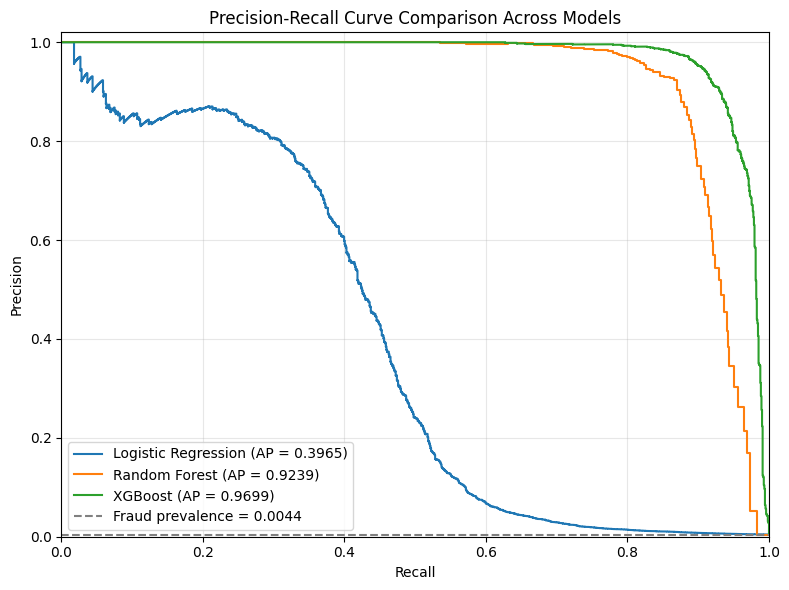

In [187]:
fig, ax = plt.subplots(figsize=(8, 6))

for model_name in model_names:
    probabilities = baselines[model_name].predict_proba(X_validation[feature_columns])[:, 1]
    precision_values, recall_values, _ = precision_recall_curve(y_validation, probabilities)
    average_precision = average_precision_score(y_validation, probabilities)
    ax.step(recall_values, precision_values, where='post',
            label=f'{model_name} (AP = {average_precision:.4f})')

ax.axhline(y_validation.mean(), color='gray', linestyle='--',
           label=f'Fraud prevalence = {y_validation.mean():.4f}')
ax.set(xlabel='Recall', ylabel='Precision', title='Precision-Recall Curve Comparison Across Models',
       xlim=(0, 1), ylim=(0, 1.02))
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
plt.close(fig)

### Time Series Cross-Validation: Stability Check

In [188]:
cv_timestamps = timestamps.loc[timestamps < test_start]
unique_times = np.sort(cv_timestamps.unique())
time_cv = TimeSeriesSplit(n_splits=3)
cv_results = []

if len(unique_times) <= time_cv.n_splits:
    raise ValueError('Not enough unique timestamps for three time-series folds.')

for fold, (train_positions, validation_positions) in enumerate(time_cv.split(unique_times), start=1):
    fold_validation_start = unique_times[validation_positions[0]]
    fold_validation_end = unique_times[validation_positions[-1]]
    fold_train_index = cv_timestamps.index[cv_timestamps < fold_validation_start]
    fold_validation_index = cv_timestamps.index[
        (cv_timestamps >= fold_validation_start) & (cv_timestamps <= fold_validation_end)
    ]
    y_fold_train, y_fold_validation = y.loc[fold_train_index], y.loc[fold_validation_index]

    if y_fold_train.nunique() != 2 or y_fold_validation.nunique() != 2:
        raise ValueError(f'Fold {fold} requires both fraud classes in its training and validation periods.')
    
    print(f'Training time-series fold {fold}: XGBoost with all features')
    
    fold_model = make_model('XGBoost', feature_columns)
    fold_model.fit(X.loc[fold_train_index, feature_columns], y_fold_train)
    fold_metrics, _ = evaluate(fold_model, X.loc[fold_validation_index, feature_columns], y_fold_validation)
    cv_results.append({
        'Fold': fold,
        'Train start': cv_timestamps.loc[fold_train_index].min(),
        'Train end': cv_timestamps.loc[fold_train_index].max(),
        'Validation start': cv_timestamps.loc[fold_validation_index].min(),
        'Validation end': cv_timestamps.loc[fold_validation_index].max(),
        'Train transactions': len(fold_train_index),
        'Validation transactions': len(fold_validation_index),
        'Validation fraud prevalence': y_fold_validation.mean(),
        **fold_metrics,
    })

cv_results = pd.DataFrame(cv_results)
display(cv_results)

Training time-series fold 1: XGBoost with all features
Training time-series fold 2: XGBoost with all features
Training time-series fold 3: XGBoost with all features


,Fold,Train start,Train end,Validation start,Validation end,Train transactions,Validation transactions,Validation fraud prevalence,PR-AUC (Average Precision),ROC-AUC,Recall,Precision,F1
0,1,2019-01-01 00:00:18,2019-06-29 01:43:20,2019-06-29 01:44:09,2019-12-01 12:27:06,392846,393488,0.005167,0.958700,0.999230,0.850959,0.980170,0.911006
1,2,2019-01-01 00:00:18,2019-12-01 12:27:06,2019-12-01 12:27:07,2020-05-08 09:03:50,786334,394498,0.005473,0.977470,0.999660,0.873553,0.983316,0.925190
2,3,2019-01-01 00:00:18,2020-05-08 09:03:50,2020-05-08 09:05:48,2020-10-03 00:58:23,1180832,393702,0.004907,0.971127,0.999269,0.868012,0.985891,0.923204


# 5. XGBoost Hyperparameter Tuning

In [189]:
N_TRIALS = 15
N_TUNING_FOLDS = 3
N_TUNING_FEATURES = 20

tuned_features = rankings['XGBoost']['feature'].head(N_TUNING_FEATURES).tolist()
train_times = timestamps.loc[train_index]
unique_train_times = np.sort(train_times.unique())

if len(unique_train_times) <= N_TUNING_FOLDS:
    raise ValueError('Not enough unique training timestamps for tuning folds.')

tuning_folds = []
fold_descriptions = []

for fold, (_, validation_positions) in enumerate(
        TimeSeriesSplit(n_splits=N_TUNING_FOLDS).split(unique_train_times), start=1):
    start = unique_train_times[validation_positions[0]]
    end = unique_train_times[validation_positions[-1]]
    fold_train_index = train_times.index[train_times < start]
    fold_validation_index = train_times.index[(train_times >= start) & (train_times <= end)]

    if y.loc[fold_train_index].nunique() != 2 or y.loc[fold_validation_index].nunique() != 2:
        raise ValueError(f'Tuning fold {fold} requires both fraud classes in train and validation.')
    
    print(f'Computing feature ranking for tuning fold {fold}')
    
    ranking_model = make_model('XGBoost', feature_columns)
    ranking_model.fit(X.loc[fold_train_index, feature_columns], y.loc[fold_train_index])
    fold_features = feature_importance(ranking_model, feature_columns)['feature'].head(N_TUNING_FEATURES).tolist()
    tuning_folds.append((fold_train_index, fold_validation_index, fold_features))
    fold_descriptions.append({
        'Fold': fold, 'Train start': train_times.loc[fold_train_index].min(),
        'Train end': train_times.loc[fold_train_index].max(),
        'Validation start': train_times.loc[fold_validation_index].min(),
        'Validation end': train_times.loc[fold_validation_index].max(),
        'Train transactions': len(fold_train_index),
        'Validation transactions': len(fold_validation_index),
    })

display(pd.DataFrame(fold_descriptions))


Computing feature ranking for tuning fold 1
Computing feature ranking for tuning fold 2
Computing feature ranking for tuning fold 3


,Fold,Train start,Train end,Validation start,Validation end,Train transactions,Validation transactions
0,1,2019-01-01 00:00:18,2019-06-03 15:06:44,2019-06-03 15:06:56,2019-10-02 21:39:26,323378,324258
1,2,2019-01-01 00:00:18,2019-10-02 21:39:26,2019-10-02 21:39:44,2020-01-29 02:26:28,647636,325483
2,3,2019-01-01 00:00:18,2020-01-29 02:26:28,2020-01-29 02:27:39,2020-06-21 12:13:37,973119,323556


In [190]:
optuna_objective = partial(
    tuning_objective, X=X, y=y, tuning_folds=tuning_folds,
    categorical_columns=categorical_columns,
)

study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(optuna_objective, n_trials=N_TRIALS)
best_params = study.best_params.copy()

print('Best mean fold average precision:', study.best_value)
print('Best parameters:', best_params)
display(study.trials_dataframe(attrs=('number', 'value', 'params', 'user_attrs', 'state')))


[I 2026-11-08 21:38:47,822] A new study created in memory with name: no-name-03ede90a-cb8c-443c-8921-711d7c7fb5b2
[I 2026-11-08 21:39:12,815] Trial 0 finished with value: 0.9716774328820823 and parameters: {'n_estimators': 212, 'max_depth': 8, 'learning_rate': 0.10790061933340454, 'min_child_weight': 6, 'subsample': 0.7468055921327309, 'colsample_bytree': 0.7467983561008608, 'scale_pos_weight': 1.3927723945289012}. Best is trial 0 with value: 0.9716774328820823.
[I 2026-11-08 21:39:43,846] Trial 1 finished with value: 0.9771451793049474 and parameters: {'n_estimators': 360, 'max_depth': 6, 'learning_rate': 0.10211806418789517, 'min_child_weight': 1, 'subsample': 0.9909729556485982, 'colsample_bytree': 0.9497327922401265, 'scale_pos_weight': 3.357296705351792}. Best is trial 1 with value: 0.9771451793049474.
[I 2026-11-08 21:39:58,209] Trial 2 finished with value: 0.9283015234975553 and parameters: {'n_estimators': 154, 'max_depth': 4, 'learning_rate': 0.04029695576831731, 'min_child_we

Best mean fold average precision: 0.9773803336096004
Best parameters: {'n_estimators': 327, 'max_depth': 7, 'learning_rate': 0.12906348644245946, 'min_child_weight': 1, 'subsample': 0.9943061226066894, 'colsample_bytree': 0.931578875128058, 'scale_pos_weight': 3.6530101047667456}


,number,value,params_colsample_bytree,params_learning_rate,params_max_depth,params_min_child_weight,params_n_estimators,params_scale_pos_weight,params_subsample,user_attrs_fold_average_precision,state
0,0,0.971677,0.746798,0.107901,8,6,212,1.392772,0.746806,"[0.952858903254667, 0.9775732160916665, 0.9846...",COMPLETE
1,1,0.977145,0.949733,0.102118,6,1,360,3.357297,0.990973,"[0.9646775982539255, 0.9809490845204354, 0.985...",COMPLETE
2,2,0.928302,0.787369,0.040297,4,6,154,32.781877,0.829584,"[0.9091024781957434, 0.9283214757587366, 0.947...",COMPLETE
3,3,0.931080,0.759902,0.046493,4,5,141,18.785426,0.935553,"[0.9099518973572814, 0.9354156180505596, 0.947...",COMPLETE
4,4,0.948561,0.984666,0.081017,3,2,278,246.596912,0.719515,"[0.9348739691862806, 0.9458728079290017, 0.964...",COMPLETE
5,5,0.945691,0.736611,0.025044,4,7,343,16.850518,0.832046,"[0.9273180156646169, 0.949360805727548, 0.9603...",COMPLETE
6,6,0.948192,0.856020,0.036292,8,7,110,22.608287,0.793513,"[0.9243682253897991, 0.9523521053936376, 0.967...",COMPLETE
7,7,0.973305,0.879370,0.119169,8,10,155,192.129593,0.968448,"[0.9570959498019882, 0.9782838489630555, 0.984...",COMPLETE
8,8,0.860426,0.781405,0.022195,4,4,126,112.949236,0.816603,"[0.843487487110495, 0.8473269461221347, 0.8904...",COMPLETE
9,9,0.950704,0.722365,0.069779,4,2,207,278.380369,0.940659,"[0.9344397747294302, 0.9500900823455554, 0.967...",COMPLETE


# 6. Validation Threshold Selection

In [191]:
MIN_PRECISION = 0.85

tuned_train_model = make_tuned_xgboost(tuned_features, best_params)
tuned_train_model.fit(X_train[tuned_features], y_train)
validation_probabilities = tuned_train_model.predict_proba(X_validation[tuned_features])[:, 1]
selected_threshold = select_precision_threshold(y_validation, validation_probabilities, MIN_PRECISION)
validation_predictions = (validation_probabilities >= selected_threshold).astype(int)
validation_threshold_metrics = {
    'Threshold': selected_threshold,
    'Alert count': int(validation_predictions.sum()),
    'Alert rate': validation_predictions.mean(),
    'PR-AUC (Average Precision)': average_precision_score(y_validation, validation_probabilities),
    'ROC-AUC': roc_auc_score(y_validation, validation_probabilities),
    'Recall': recall_score(y_validation, validation_predictions, zero_division=0),
    'Precision': precision_score(y_validation, validation_predictions, zero_division=0),
    'F1': f1_score(y_validation, validation_predictions, zero_division=0),
}

display(pd.DataFrame([validation_threshold_metrics]))
print('Tuned validation confusion matrix:')
display_confusion_matrix(confusion_matrix(y_validation, validation_predictions, labels=[0, 1]))


,Threshold,Alert count,Alert rate,PR-AUC (Average Precision),ROC-AUC,Recall,Precision,F1
0,0.039263,1380,0.004967,0.979372,0.999464,0.963145,0.852174,0.904268


Tuned validation confusion matrix:


Predicted,Negative,Positive
Actual,,
Negative,"True Negative: 276,434",False Positive: 204
Positive,False Negative: 45,"True Positive: 1,176"


### Validation Threshold Comparison

In [192]:
threshold_comparison = []

for threshold in np.arange(1, 21) / 20:
    predictions = (validation_probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_validation, predictions, labels=[0, 1]).ravel()
    threshold_comparison.append({
        'Threshold': threshold,
        'Alert count': int(predictions.sum()),
        'Alert rate': predictions.mean(),
        'Recall': recall_score(y_validation, predictions, zero_division=0),
        'Precision': precision_score(y_validation, predictions, zero_division=0),
        'F1': f1_score(y_validation, predictions, zero_division=0),
        'True Positive': tp,
        'False Positive': fp,
        'False Negative': fn,
        'True Negative': tn,
    })

threshold_comparison = pd.DataFrame(threshold_comparison)
display(threshold_comparison)

,Threshold,Alert count,Alert rate,Recall,Precision,F1,True Positive,False Positive,False Negative,True Negative
0,0.05,1346,0.004844,0.961507,0.872214,0.914686,1174,172,47,276466
1,0.10,1286,0.004628,0.954955,0.906687,0.930195,1166,120,55,276518
2,0.15,1245,0.004481,0.945946,0.927711,0.936740,1155,90,66,276548
3,0.20,1225,0.004409,0.941032,0.937959,0.939493,1149,76,72,276562
4,0.25,1210,0.004355,0.936937,0.945455,0.941176,1144,66,77,276572
5,0.30,1193,0.004294,0.931204,0.953060,0.942005,1137,56,84,276582
6,0.35,1180,0.004247,0.928747,0.961017,0.944606,1134,46,87,276592
7,0.40,1173,0.004222,0.925471,0.963342,0.944027,1130,43,91,276595
8,0.45,1159,0.004171,0.918100,0.967213,0.942017,1121,38,100,276600
9,0.50,1149,0.004135,0.911548,0.968668,0.939241,1113,36,108,276602


# 7. Tuned Final Model and Test Evaluation

In [193]:
train_validation_index = train_index.append(validation_index)
X_train_validation = X.loc[train_validation_index, tuned_features]
y_train_validation = y.loc[train_validation_index]
final_model = make_tuned_xgboost(tuned_features, best_params)

print('Training final tuned XGBoost with 20 features')

final_model.fit(X_train_validation, y_train_validation)

if y_test.nunique() != 2:
    raise ValueError('The test split must contain both fraud and non-fraud transactions.')

test_probabilities = final_model.predict_proba(X_test[tuned_features])[:, 1]
test_predictions = (test_probabilities >= selected_threshold).astype(int)
test_metrics = {
    'Model': 'Tuned XGBoost',
    'Features': len(tuned_features),
    'Threshold': selected_threshold,
    'Test fraud prevalence': y_test.mean(),
    'Alert count': int(test_predictions.sum()),
    'Alert rate': test_predictions.mean(),
    'PR-AUC (Average Precision)': average_precision_score(y_test, test_probabilities),
    'ROC-AUC': roc_auc_score(y_test, test_probabilities),
    'Recall': recall_score(y_test, test_predictions, zero_division=0),
    'Precision': precision_score(y_test, test_predictions, zero_division=0),
    'F1': f1_score(y_test, test_predictions, zero_division=0),
}
test_matrix = confusion_matrix(y_test, test_predictions, labels=[0, 1])

display(pd.DataFrame([test_metrics]))
print('Test confusion matrix:')
display_confusion_matrix(test_matrix)

Training final tuned XGBoost with 20 features


,Model,Features,Threshold,Test fraud prevalence,Alert count,Alert rate,PR-AUC (Average Precision),ROC-AUC,Recall,Precision,F1
0,Tuned XGBoost,20,0.039263,0.003325,1080,0.003887,0.978552,0.999741,0.967532,0.827778,0.892216


Test confusion matrix:


Predicted,Negative,Positive
Actual,,
Negative,"True Negative: 276,750",False Positive: 186
Positive,False Negative: 30,True Positive: 894


### Final Model Confusion Matrix

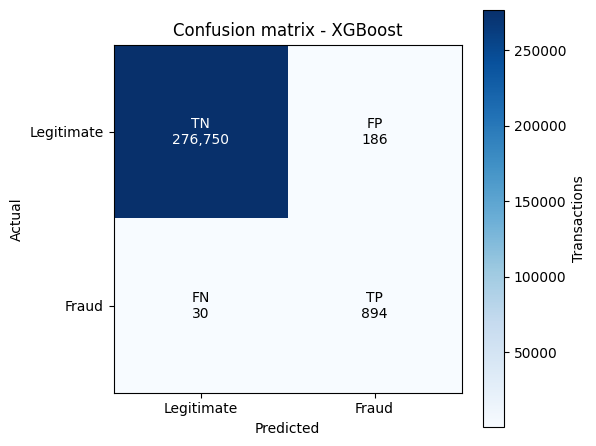

In [194]:
fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(test_matrix, cmap='Blues')
fig.colorbar(image, ax=ax, label='Transactions')
matrix_labels = [['TN', 'FP'], ['FN', 'TP']]

for row in range(2):
    for column in range(2):
        ax.text(column, row, f'{matrix_labels[row][column]}\n{test_matrix[row, column]:,}',
                ha='center', va='center',
                color='white' if test_matrix[row, column] > test_matrix.max() / 2 else 'black')
        
ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=['Legitimate', 'Fraud'],
       yticklabels=['Legitimate', 'Fraud'], xlabel='Predicted', ylabel='Actual',
       title='Confusion matrix - XGBoost')
plt.tight_layout()
plt.show()
plt.close(fig)

### Threshold Metric Plot on Validation

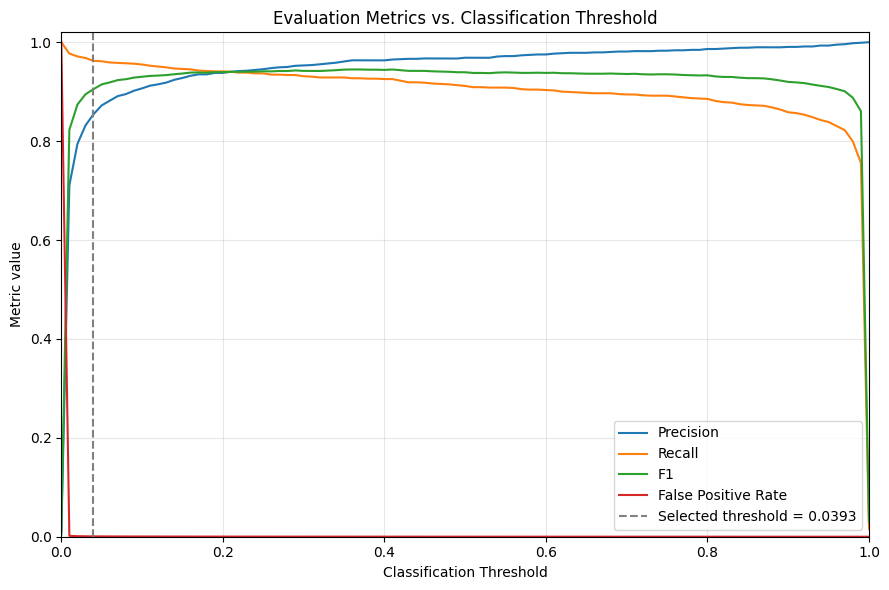

In [195]:
threshold_grid = np.linspace(0, 1, 101)
threshold_rows = []

for threshold in threshold_grid:
    predictions = (validation_probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_validation, predictions, labels=[0, 1]).ravel()
    threshold_rows.append({
        'Threshold': threshold,
        'Precision': precision_score(y_validation, predictions, zero_division=0),
        'Recall': recall_score(y_validation, predictions, zero_division=0),
        'F1': f1_score(y_validation, predictions, zero_division=0),
        'False Positive Rate': fp / (fp + tn),
    })

threshold_metrics = pd.DataFrame(threshold_rows)

fig, ax = plt.subplots(figsize=(9, 6))

for metric in ['Precision', 'Recall', 'F1', 'False Positive Rate']:
    ax.plot(threshold_metrics['Threshold'], threshold_metrics[metric], label=metric)
    
ax.axvline(selected_threshold, color='gray', linestyle='--',
           label=f'Selected threshold = {selected_threshold:.4f}')
ax.set(xlabel='Classification Threshold', ylabel='Metric value',
       title='Evaluation Metrics vs. Classification Threshold', xlim=(0, 1), ylim=(0, 1.02))
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
plt.close(fig)

# 8. Baseline XGBoost Test Comparison

In [196]:
baseline_final_model = make_model('XGBoost', tuned_features)

print('Training baseline XGBoost with 20 features on train + validation')

baseline_final_model.fit(X_train_validation, y_train_validation)
baseline_test_probabilities = baseline_final_model.predict_proba(X_test[tuned_features])[:, 1]

def test_comparison_metrics(name, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)
    metrics = {
        'Model': name,
        'Threshold': threshold,
        'Alert count': int(predictions.sum()),
        'Alert rate': predictions.mean(),
        'PR-AUC (Average Precision)': average_precision_score(y_test, probabilities),
        'ROC-AUC': roc_auc_score(y_test, probabilities),
        'Recall': recall_score(y_test, predictions, zero_division=0),
        'Precision': precision_score(y_test, predictions, zero_division=0),
        'F1': f1_score(y_test, predictions, zero_division=0),
    }

    return metrics, confusion_matrix(y_test, predictions, labels=[0, 1])

comparison_cases = [
    ('Baseline XGBoost', baseline_test_probabilities, 0.5),
    ('Tuned XGBoost', test_probabilities, 0.5),
    ('Tuned XGBoost', test_probabilities, selected_threshold),
]
comparison_metrics = []
comparison_matrices = []

for name, probabilities, threshold in comparison_cases:
    metrics, matrix = test_comparison_metrics(name, probabilities, threshold)
    comparison_metrics.append(metrics)
    comparison_matrices.append(matrix)

test_comparison = pd.DataFrame(comparison_metrics)
display(test_comparison)

for (name, _, threshold), matrix in zip(comparison_cases, comparison_matrices):
    print(f'{name} - threshold {threshold:.6f}:')
    display_confusion_matrix(matrix)

Training baseline XGBoost with 20 features on train + validation


,Model,Threshold,Alert count,Alert rate,PR-AUC (Average Precision),ROC-AUC,Recall,Precision,F1
0,Baseline XGBoost,0.500000,832,0.002994,0.973252,0.999652,0.879870,0.977163,0.925968
1,Tuned XGBoost,0.500000,867,0.003120,0.978552,0.999741,0.905844,0.965398,0.934673
2,Tuned XGBoost,0.039263,1080,0.003887,0.978552,0.999741,0.967532,0.827778,0.892216


Baseline XGBoost - threshold 0.500000:


Predicted,Negative,Positive
Actual,,
Negative,"True Negative: 276,917",False Positive: 19
Positive,False Negative: 111,True Positive: 813


Tuned XGBoost - threshold 0.500000:


Predicted,Negative,Positive
Actual,,
Negative,"True Negative: 276,906",False Positive: 30
Positive,False Negative: 87,True Positive: 837


Tuned XGBoost - threshold 0.039263:


Predicted,Negative,Positive
Actual,,
Negative,"True Negative: 276,750",False Positive: 186
Positive,False Negative: 30,True Positive: 894


# 9. SHAP Analysis

SHAP sample: 10,000 test transactions


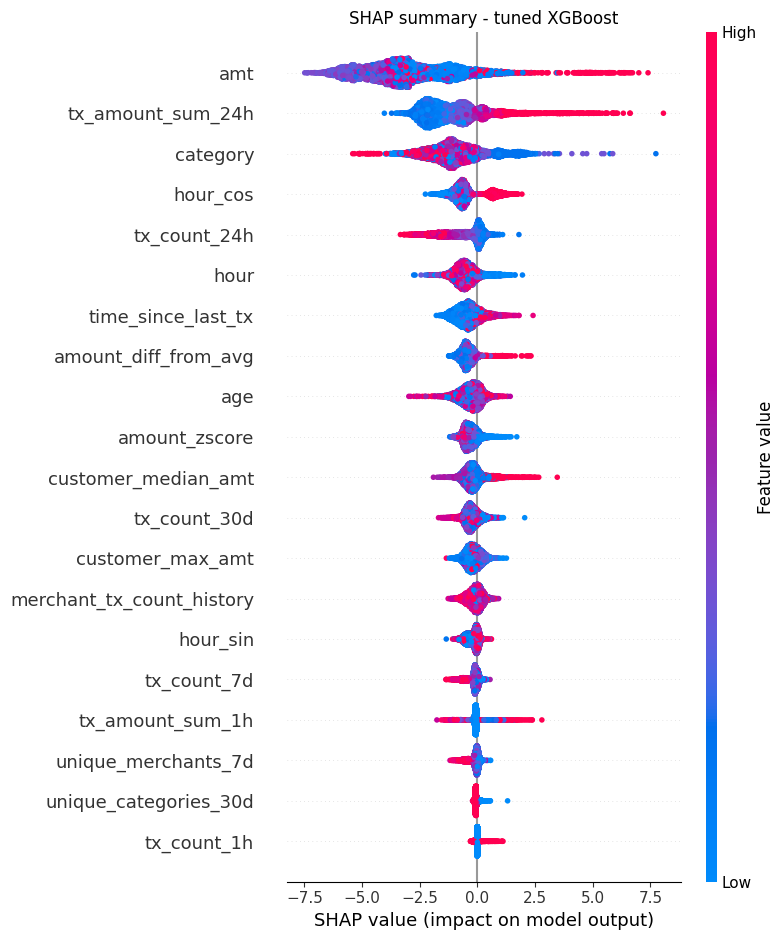

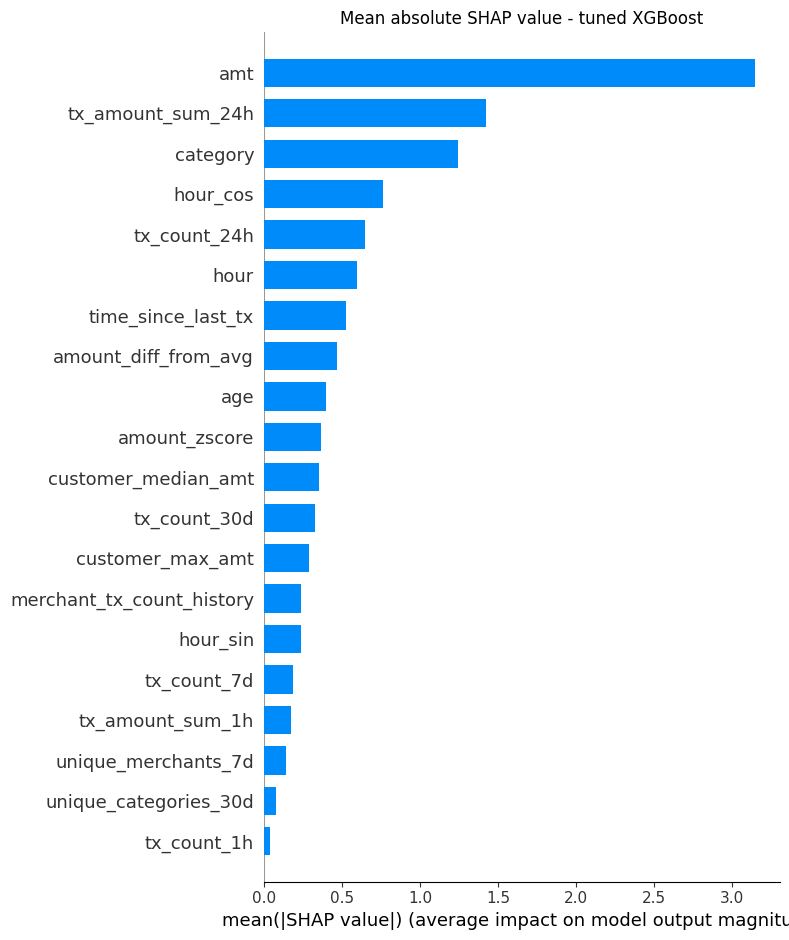

In [197]:
SHAP_SAMPLE_SIZE = 10000

shap_test = X_test[tuned_features]
shap_sample = shap_test.sample(
    n=min(SHAP_SAMPLE_SIZE, len(shap_test)), random_state=42
)
preprocessor = final_model.named_steps['preprocessor']
shap_features = pd.DataFrame(
    preprocessor.transform(shap_sample),
    columns=preprocessor.get_feature_names_out(),
    index=shap_sample.index,
)
explainer = shap.TreeExplainer(final_model.named_steps['classifier'])
shap_values = explainer.shap_values(shap_features)

print(f'SHAP sample: {len(shap_sample):,} test transactions')

shap.summary_plot(shap_values, shap_features, max_display=len(tuned_features), show=False)
plt.title('SHAP summary - tuned XGBoost')
plt.tight_layout()
plt.show()
plt.close()

shap.summary_plot(shap_values, shap_features, plot_type='bar',
                  max_display=len(tuned_features), show=False)
plt.title('Mean absolute SHAP value - tuned XGBoost')
plt.tight_layout()
plt.show()
plt.close()

### Fraud-only SHAP Analysis

Actual test frauds explained: 924
Detected: 894; missed: 30


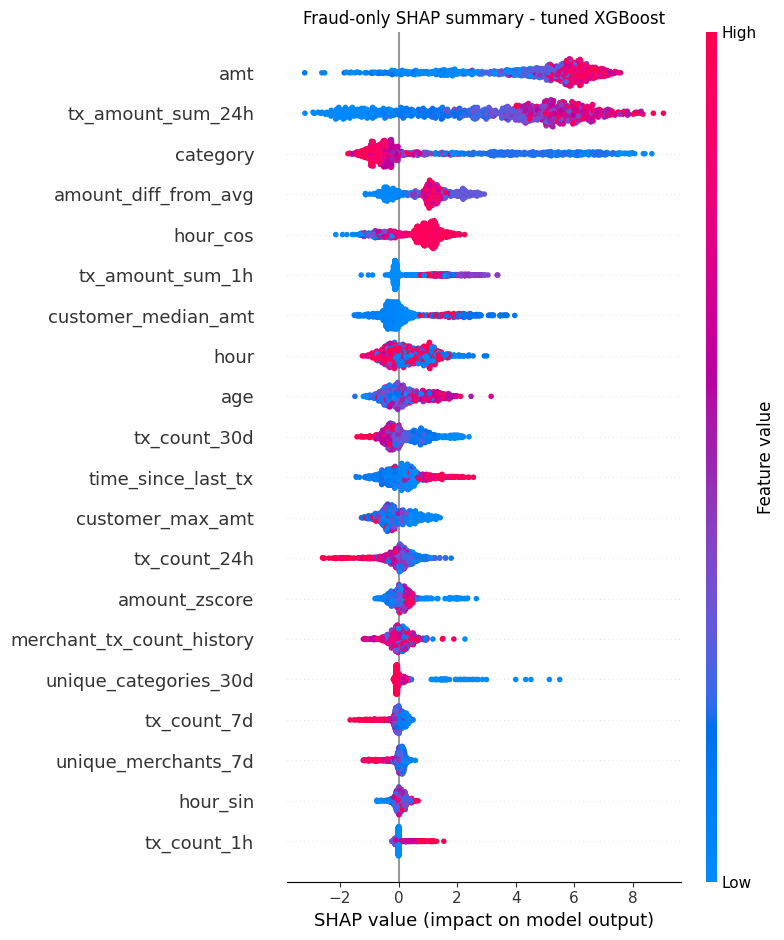

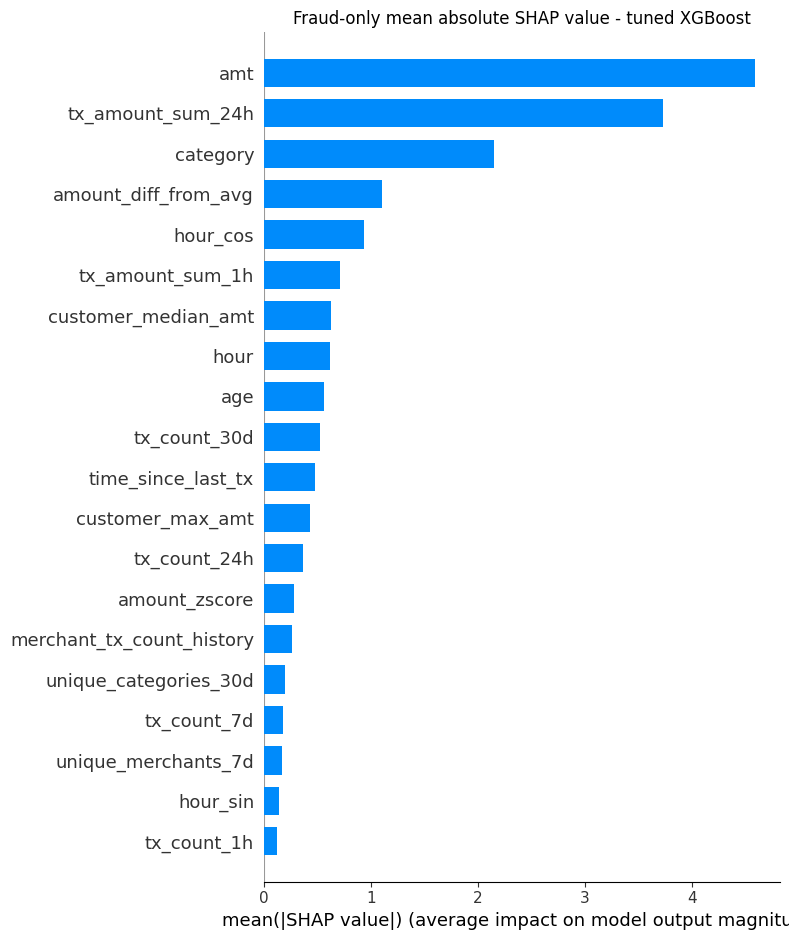

In [198]:
if not X_test.index.equals(y_test.index):
    raise ValueError('Test features and labels must have the same indices and order.')

fraud_test = shap_test.loc[y_test == 1]

if fraud_test.empty:
    raise ValueError('Fraud-only SHAP requires at least one actual fraud in the test period.')

fraud_sample = fraud_test
fraud_shap_features = pd.DataFrame(
    preprocessor.transform(fraud_sample),
    columns=preprocessor.get_feature_names_out(),
    index=fraud_sample.index,
)
fraud_shap_values = explainer.shap_values(fraud_shap_features)
fraud_probabilities = pd.Series(test_probabilities, index=X_test.index).loc[fraud_sample.index]
detected_frauds = int((fraud_probabilities >= selected_threshold).sum())

print(f'Actual test frauds explained: {len(fraud_sample):,}')
print(f'Detected: {detected_frauds:,}; missed: {len(fraud_sample) - detected_frauds:,}')

shap.summary_plot(fraud_shap_values, fraud_shap_features,
                  max_display=len(tuned_features), show=False)
plt.title('Fraud-only SHAP summary - tuned XGBoost')
plt.tight_layout()
plt.show()
plt.close()

shap.summary_plot(fraud_shap_values, fraud_shap_features, plot_type='bar',
                  max_display=len(tuned_features), show=False)
plt.title('Fraud-only mean absolute SHAP value - tuned XGBoost')
plt.tight_layout()
plt.show()
plt.close()